In [16]:
from google.colab import files

arquivos_video = files.upload()
video_path = next(iter(arquivos_video))

print("Vídeo carregado:", video_path)

Saving Video_pluma.mp4 to Video_pluma.mp4
Vídeo carregado: Video_pluma.mp4


In [17]:
import cv2

captura = cv2.VideoCapture(video_path)

fps = captura.get(cv2.CAP_PROP_FPS)
total_frames = int(captura.get(cv2.CAP_PROP_FRAME_COUNT))
largura = int(captura.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(captura.get(cv2.CAP_PROP_FRAME_HEIGHT))
duracao = total_frames / fps

captura.release()

print(f"Resolução: {largura} × {altura}")
print(f"FPS: {fps:.2f}")
print(f"Quantidade de quadros: {total_frames}")
print(f"Duração: {duracao:.2f} segundos")

Resolução: 720 × 1292
FPS: 29.62
Quantidade de quadros: 484
Duração: 16.34 segundos


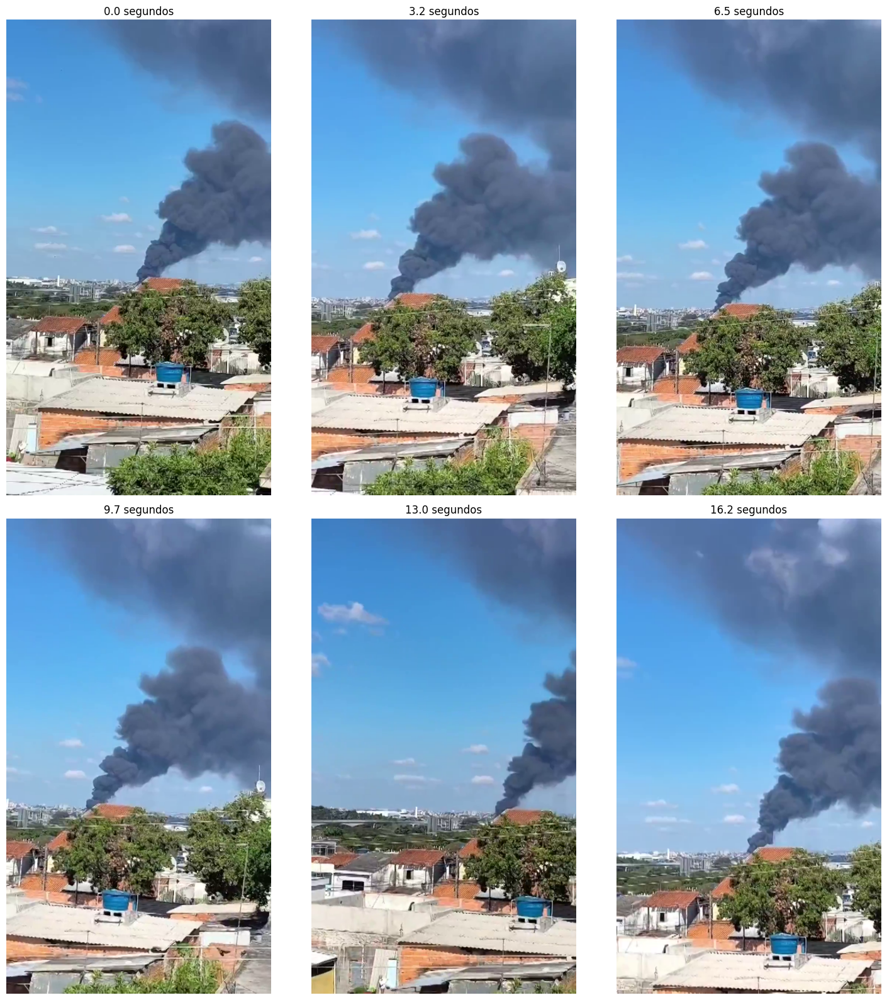

In [18]:
import numpy as np
import matplotlib.pyplot as plt

tempos = np.linspace(
    0,
    max(0, duracao - 0.1),
    6
)

captura = cv2.VideoCapture(video_path)

fig, axes = plt.subplots(2, 3, figsize=(15, 16))
axes = axes.flatten()

for ax, tempo in zip(axes, tempos):
    captura.set(cv2.CAP_PROP_POS_MSEC, tempo * 1000)

    sucesso, frame = captura.read()

    if sucesso:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        ax.imshow(frame_rgb)
        ax.set_title(f"{tempo:.1f} segundos")
    else:
        ax.set_title("Não foi possível ler")

    ax.axis("off")

captura.release()
plt.tight_layout()
plt.show()

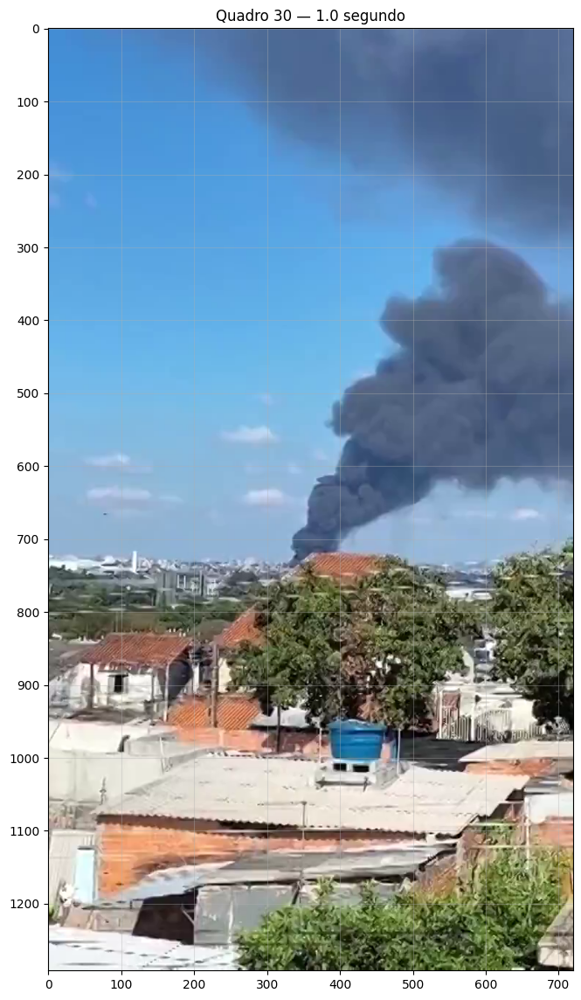

In [19]:
tempo_prompt = 1.0
frame_prompt = round(tempo_prompt * fps)

captura = cv2.VideoCapture(video_path)
captura.set(cv2.CAP_PROP_POS_FRAMES, frame_prompt)

sucesso, quadro_prompt_bgr = captura.read()
captura.release()

if not sucesso:
    raise ValueError("Não foi possível extrair o quadro escolhido.")

quadro_prompt = cv2.cvtColor(
    quadro_prompt_bgr,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 14))
plt.imshow(quadro_prompt)
plt.xticks(range(0, largura, 100))
plt.yticks(range(0, altura, 100))
plt.grid(alpha=0.35)
plt.title(
    f"Quadro {frame_prompt} — "
    f"{tempo_prompt:.1f} segundo"
)
plt.show()

In [20]:
pontos_positivos_video = [
    [600, 90],   # fumaça na parte superior
    [560, 360],  # região densa superior
    [520, 460],  # centro da pluma
    [460, 560],  # região intermediária
    [395, 660],  # parte inferior
    [355, 715]   # próximo à origem da fumaça
]

pontos_negativos_video = [
    [150, 150],  # céu azul superior esquerdo
    [150, 350],  # céu azul
    [250, 560],  # céu à esquerda da pluma
    [650, 680],  # céu/nuvem abaixo da região principal
    [250, 760]   # cidade, fora da fumaça
]

rotulos_video = (
    [1] * len(pontos_positivos_video)
    + [0] * len(pontos_negativos_video)
)

print("Positivos:", len(pontos_positivos_video))
print("Negativos:", len(pontos_negativos_video))
print("Rótulos:", rotulos_video)

Positivos: 6
Negativos: 5
Rótulos: [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]


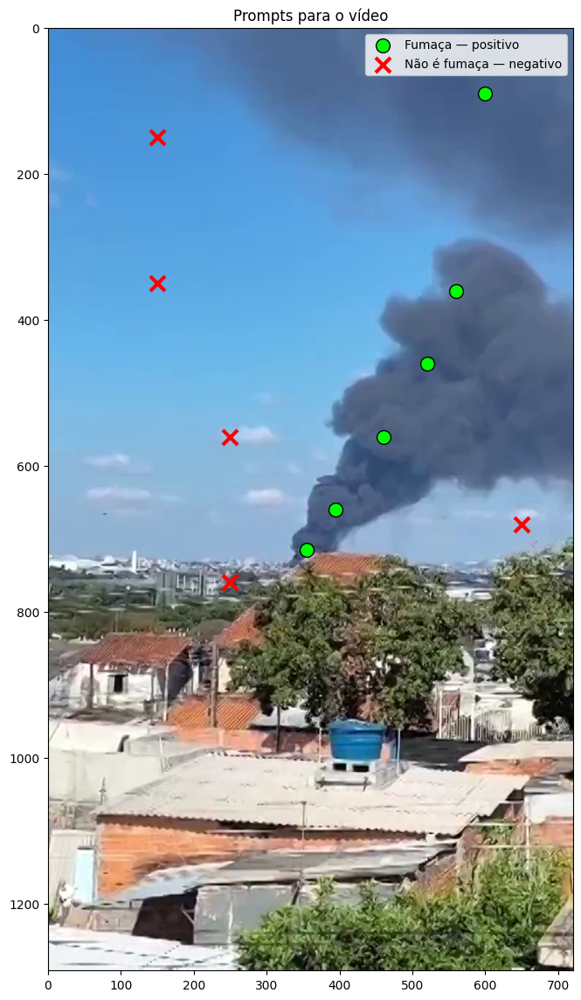

In [21]:
plt.figure(figsize=(10, 14))
plt.imshow(quadro_prompt)

plt.scatter(
    [p[0] for p in pontos_positivos_video],
    [p[1] for p in pontos_positivos_video],
    c="lime",
    s=130,
    edgecolors="black",
    label="Fumaça — positivo"
)

plt.scatter(
    [p[0] for p in pontos_negativos_video],
    [p[1] for p in pontos_negativos_video],
    c="red",
    s=150,
    marker="x",
    linewidths=3,
    label="Não é fumaça — negativo"
)

plt.xlim(0, largura)
plt.ylim(altura, 0)
plt.legend()
plt.title("Prompts para o vídeo")
plt.show()

In [22]:
video_recortado = "/content/video_pluma_recortado.mp4"

video_para_segmentar = video_recortado

print("Vídeo que será processado:", video_para_segmentar)

print("Vídeo recortado:", video_recortado)
captura = cv2.VideoCapture(video_path)

fps_original = captura.get(cv2.CAP_PROP_FPS)
largura_original = int(
    captura.get(cv2.CAP_PROP_FRAME_WIDTH)
)
altura_original = int(
    captura.get(cv2.CAP_PROP_FRAME_HEIGHT)
)

captura.set(
    cv2.CAP_PROP_POS_MSEC,
    tempo_prompt * 1000
)

codec = cv2.VideoWriter_fourcc(*"mp4v")

gravador = cv2.VideoWriter(
    video_recortado,
    codec,
    fps_original,
    (largura_original, altura_original)
)

while True:
    sucesso, frame = captura.read()

    if not sucesso:
        break

    gravador.write(frame)

captura.release()
gravador.release()

print("Vídeo recortado:", video_recortado)

Vídeo que será processado: /content/video_pluma_recortado.mp4
Vídeo recortado: /content/video_pluma_recortado.mp4
Vídeo recortado: /content/video_pluma_recortado.mp4


In [10]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.6 MB/s eta 0:00:00


In [23]:
import torch

print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("A execução continuará na CPU.")

GPU disponível: True
GPU: Tesla T4


In [24]:
from ultralytics.models.sam import SAM2VideoPredictor

configuracao_video = {
    "conf": 0.25,
    "task": "segment",
    "mode": "predict",
    "imgsz": 640,
    "model": "sam2.1_t.pt",
    "device": 0,
    "save": True,
    "project": "/content/resultados_sam2",
    "name": "pluma_video",
    "exist_ok": True
}

predictor_video = SAM2VideoPredictor(
    overrides=configuracao_video
)

In [25]:
pontos_sam_video = [
    pontos_positivos_video + pontos_negativos_video
]

labels_sam_video = [
    rotulos_video
]

gerador_resultados = predictor_video(
    source=video_para_segmentar,
    points=pontos_sam_video,
    labels=labels_sam_video,
    stream=True
)

quantidade_processada = 0

for quantidade_processada, resultado in enumerate(
    gerador_resultados,
    start=1
):
    if quantidade_processada % 30 == 0:
        print(
            f"{quantidade_processada} quadros processados"
        )

print(
    "Processamento concluído:",
    quantidade_processada,
    "quadros"
)


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
video 1/1 (frame 1/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 2534.1ms
video 1/1 (frame 2/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 126.4ms
video 1/1 (frame 3/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 112.0ms
video 1/1 (frame 4/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 73.7ms
video 1/1 (frame 5/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 78.9ms
video 1/1 (frame 6/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 74.6ms
video 1/1 (frame 7/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 78.5ms
video 1/1 (frame 8/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 89.5ms
video 1/1 (frame 9/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 83.8ms
video 1/1 (frame 10/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 84.5ms
video 1/1 (frame 11/454) /content/video_pluma_recortado.mp4: 640x640 1 0, 83.2ms
video 1/1 (frame 12/454) /con

In [26]:
import glob
import os

arquivos_saida = glob.glob(
    "/content/resultados_sam2/pluma_video/**/*",
    recursive=True
)

for arquivo in arquivos_saida:
    if os.path.isfile(arquivo):
        print(arquivo)

/content/resultados_sam2/pluma_video/video_pluma_recortado.avi


In [27]:
videos_saida = [
    arquivo
    for arquivo in arquivos_saida
    if arquivo.lower().endswith((".mp4", ".avi"))
]

print(videos_saida)

['/content/resultados_sam2/pluma_video/video_pluma_recortado.avi']


In [ ]:
from IPython.display import Video, display

if videos_saida:
    display(
        Video(
            videos_saida[0],
            embed=True,
            width=500
        )
    )
else:
    print("O arquivo de vídeo não foi encontrado.")

In [30]:
video_avi = videos_saida[0]
video_mp4 = "/content/pluma_segmentada_sam2.mp4"

!ffmpeg -y -i "$video_avi" \
    -c:v libx264 \
    -pix_fmt yuv420p \
    "$video_mp4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [31]:
from IPython.display import Video, display

display(
    Video(
        video_mp4,
        embed=True,
        width=500
    )
)

In [32]:
from google.colab import files

files.download(video_mp4)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

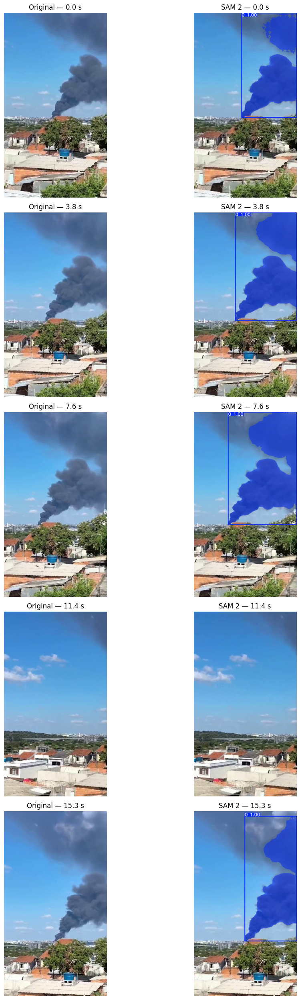

In [33]:
captura_original = cv2.VideoCapture(
    video_para_segmentar
)

captura_resultado = cv2.VideoCapture(
    video_mp4
)

total_original = int(
    captura_original.get(cv2.CAP_PROP_FRAME_COUNT)
)

total_resultado = int(
    captura_resultado.get(cv2.CAP_PROP_FRAME_COUNT)
)

total_comparacao = min(
    total_original,
    total_resultado
)

quadros_comparacao = np.linspace(
    0,
    total_comparacao - 1,
    5,
    dtype=int
)

fig, axes = plt.subplots(
    5,
    2,
    figsize=(12, 25)
)

for linha, numero_quadro in enumerate(quadros_comparacao):
    captura_original.set(
        cv2.CAP_PROP_POS_FRAMES,
        numero_quadro
    )

    captura_resultado.set(
        cv2.CAP_PROP_POS_FRAMES,
        numero_quadro
    )

    sucesso_original, frame_original = (
        captura_original.read()
    )

    sucesso_resultado, frame_resultado = (
        captura_resultado.read()
    )

    if sucesso_original:
        frame_original = cv2.cvtColor(
            frame_original,
            cv2.COLOR_BGR2RGB
        )

        axes[linha, 0].imshow(frame_original)

    if sucesso_resultado:
        frame_resultado = cv2.cvtColor(
            frame_resultado,
            cv2.COLOR_BGR2RGB
        )

        axes[linha, 1].imshow(frame_resultado)

    tempo = numero_quadro / fps_original

    axes[linha, 0].set_title(
        f"Original — {tempo:.1f} s"
    )

    axes[linha, 1].set_title(
        f"SAM 2 — {tempo:.1f} s"
    )

    axes[linha, 0].axis("off")
    axes[linha, 1].axis("off")

captura_original.release()
captura_resultado.release()

plt.tight_layout()
plt.show()

## Avaliação da segmentação em vídeo

O SAM 2 processou 454 quadros utilizando uma GPU Tesla T4. Os prompts
foram fornecidos no primeiro quadro do vídeo recortado e propagados para
os quadros seguintes por meio da memória temporal do modelo.

A avaliação foi realizada observando diferentes momentos do vídeo. Foram
analisadas a permanência da máscara sobre a pluma, a inclusão indevida do
céu, a perda de regiões da fumaça e a estabilidade da segmentação durante
o movimento da câmera.

A fumaça representa um desafio porque muda continuamente de forma, apresenta
bordas difusas e possui regiões com diferentes níveis de transparência.
Além disso, parte da pluma sai dos limites da imagem. Esses fatores podem
provocar perda de detalhes, oscilações na máscara e confusão com o céu.